# ¿A quién alcanza el fuego? · Incendios del sur andino y Open Buildings

**Tarea en clase · Ciencia de Datos con Python · 21 de octubre de 2026 · Roddy Huarhua**

Reto **D · ¿A quién afecta?**, con un giro: en lugar de contar *personas* con WorldPop
(píxeles de 1 km), cuento **edificaciones una por una** con
[Google Open Buildings v3](https://sites.research.google/gr/open-buildings/), que detecta
cada techo desde imágenes satelitales de 50 cm.

Para quien trabaja en relaciones comunitarias la pregunta es concreta: cuando un incendio
quema 3 000 ha de pastizal, ¿cuántas viviendas, corrales o locales comunales quedaron
dentro o al lado del fuego?

| Paso | Qué hacemos |
|---|---|
| 1 | Abrir el raster de severidad dNBR (Sentinel-2) de 7 incendios del sur |
| 2 | Validar que las hectáreas salen bien |
| 3 | Bajar las edificaciones de Open Buildings y filtrarlas por confianza |
| 4 | Medir la distancia de cada edificación a la huella quemada (en metros, no en grados) |
| 5 | Raster → punto: ¿qué severidad tuvo el fuego donde hay techos? |
| 6 | Vector → raster: densidad de edificaciones y *zonal stats* por anillo |
| 7 | Mapa, hallazgos y limitaciones |

Sigo la estructura de la guía `sessions/07-raster/lecture/raster_aplicado.ipynb`.

## 0 · Preparación

```bash
pip install geopandas rasterio rasterstats matplotlib
```

In [1]:
import json
import warnings
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from rasterio.features import rasterize
from rasterstats import zonal_stats

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda v: f"{v:,.1f}")
plt.rcParams.update({"figure.dpi": 110, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False})

DATOS = Path("datos")
SEVERIDAD = {1: "Baja", 2: "Moderada baja", 3: "Moderada alta", 4: "Alta"}
COLORES = {1: "#facc15", 2: "#f97316", 3: "#dc2626", 4: "#7f1d1d"}

## 1 · Los datos

| Dato | Fuente | Tipo | Fecha |
|---|---|---|---|
| Huella quemada y severidad dNBR | Sentinel-2 L2A (Planetary Computer), calculado en el monitor de incendios del curso | **Raster** 1024 × 1024, ~22 m | imágenes pre y post entre el 25 set y el 15 oct de 2026 |
| Focos de calor | VIIRS S-NPP / NOAA-20 / NOAA-21 (NASA FIRMS, INPE) | Puntos | 1 jul – 17 oct 2026 |
| Edificaciones | Google Open Buildings v3, tile S2 `917` | Polígonos → centroides | imágenes hasta mayo 2023 |
| Atributos de cada incendio | Monitor de incendios del curso (distrito, cobertura) | Tabla | corte 17 oct 2026, 02:01 |
| Población a ≤ 5 km de los focos | WorldPop 2020, 1 km, calculada en el monitor | Raster → tabla | 2020 |

Elegí los **7 incendios del sur andino** (Apurímac, Cusco y Arequipa) que tienen dNBR en el
monitor. Todos caen en el mismo tile de Open Buildings, así que una sola descarga basta.

In [2]:
eventos = pd.read_csv(DATOS / "eventos.csv")
perimetros = gpd.read_file(DATOS / "perimetros_dnbr.geojson")
focos = pd.read_csv(DATOS / "focos_viirs.csv")

eventos[["evento", "distrito", "provincia", "departamento", "estado",
         "inicio", "cobertura", "huella_ha", "poblacion_5km"]]

,evento,distrito,provincia,departamento,estado,inicio,cobertura,huella_ha,poblacion_5km
0,E41216,Curahuasi,Abancay,Apurímac,Activo,2026-10-06 13:00,Pastizal,"4,528.0","3,114.0"
1,E41197,San Pedro de Cachora,Abancay,Apurímac,Activo,2026-10-06 13:00,Pastizal,"1,547.0","4,466.0"
2,E45243,Huanoquite,Paruro,Cusco,Activo,2026-10-13 13:06,Pastizal,816.0,"1,533.0"
3,E37866,Coyllurqui,Cotabambas,Apurímac,Sin actividad reciente,2026-10-01 12:54,Pastizal,"1,758.0","3,143.0"
4,E38662,Sicuani,Canchis,Cusco,Sin actividad reciente,2026-10-03 12:52,Pastizal,"2,053.0","44,869.0"
5,E39747,Alto Pichigua,Espinar,Cusco,Sin actividad reciente,2026-10-05 12:34,Pastizal,"1,420.0",657.0
6,E20624,Toro,La Unión,Arequipa,Sin actividad reciente,2026-09-01 12:52,Matorral,844.0,500.0


### Cómo se bajó Open Buildings

El archivo `open_buildings_5km.csv` ya viene en el repositorio (2,7 MB). Para rehacerlo
desde cero, cambia `DESCARGAR = True`: lee el tile `917` (340 MB comprimidos, ~3,5 millones
de edificaciones del sur del Perú) **sin guardarlo entero**, línea por línea, y se queda solo
con las que caen cerca de cada incendio. Tarda unos 2 minutos.

In [3]:
DESCARGAR = False

def descargar_open_buildings(centros, radio_grados=0.13):
    import csv, gzip, urllib.request
    url = ("https://storage.googleapis.com/open-buildings-data/v3/"
           "polygons_s2_level_4_gzip/917_buildings.csv.gz")
    filas = []
    with urllib.request.urlopen(url) as r, gzip.open(r, "rt") as g:
        lector = csv.DictReader(g)
        for f in lector:
            la, lo = float(f["latitude"]), float(f["longitude"])
            if any(abs(la - a) < radio_grados and abs(lo - b) < radio_grados for a, b in centros):
                filas.append({k: f[k] for k in ("latitude", "longitude", "area_in_meters", "confidence")})
    return pd.DataFrame(filas).astype(float)

if DESCARGAR:
    crudo = descargar_open_buildings(list(zip(eventos.lat, eventos.lon)))
    print(f"{len(crudo):,} edificaciones bajadas")

## 2 · Abrir el raster dNBR

Como en la guía: un raster es una matriz con `transform` y `crs`. Abrimos el de Curahuasi.

In [4]:
with rasterio.open(DATOS / "dnbr_E41216.tif") as src:
    sev = src.read(1)
    print(f"forma     : {sev.shape}  ({sev.size:,} píxeles)")
    print(f"CRS       : {src.crs}")
    print(f"resolución: {src.res[0]:.6f}° ≈ {src.res[0] * 111_320 * np.cos(np.radians(13.6)):.0f} m")
    print(f"nodata    : {src.nodata}   (0 = no quemado o sin dato)")

valores, cuentas = np.unique(sev, return_counts=True)
pd.DataFrame({"clase": [SEVERIDAD.get(v, "sin quemar") for v in valores], "píxeles": cuentas})

forma     : (1024, 1024)  (1,048,576 píxeles)
CRS       : EPSG:4326
resolución: 0.000216° ≈ 23 m
nodata    : 0.0   (0 = no quemado o sin dato)


,clase,píxeles
0,sin quemar,996057
1,Baja,33834
2,Moderada baja,16942
3,Moderada alta,1676
4,Alta,67


## 3 · Validar antes de creer

El monitor reporta 2 847 ha quemadas en Curahuasi. Si mi lectura del raster es correcta,
debo obtener lo mismo. Ojo: **los píxeles en grados no miden lo mismo en todas partes**,
así que el área de cada píxel se calcula con la latitud.

In [5]:
def hectareas_por_clase(ruta):
    with rasterio.open(ruta) as src:
        a = src.read(1)
        lat = (src.bounds.top + src.bounds.bottom) / 2
        ha_pixel = (src.res[0] * 111_320 * np.cos(np.radians(lat))) * (src.res[1] * 110_574) / 10_000
    return {SEVERIDAD[k]: (a == k).sum() * ha_pixel for k in SEVERIDAD}

validacion = []
for _, p in perimetros.iterrows():
    ha = hectareas_por_clase(DATOS / f"dnbr_{p.evento}.tif")
    validacion.append({"evento": p.evento, "distrito": p.distrito,
                       "ha_mi_calculo": sum(ha.values()), "ha_monitor": p.ha_dnbr,
                       "nubes_sin_dato_%": p.pct_sin_dato,
                       "pre": p.sentinel_pre, "post": p.sentinel_post})
validacion = pd.DataFrame(validacion)
validacion["diferencia_%"] = 100 * (validacion.ha_mi_calculo / validacion.ha_monitor - 1)
validacion

,evento,distrito,ha_mi_calculo,ha_monitor,nubes_sin_dato_%,pre,post,diferencia_%
0,E41216,Curahuasi,"2,847.1","2,847.0",14.0,2026-10-05,2026-10-15,0.0
1,E41197,San Pedro de Cachora,"1,450.7","1,451.0",0.0,2026-10-03,2026-10-13,-0.0
2,E45243,Huanoquite,378.8,379.0,7.0,2026-10-07,2026-10-15,-0.0
3,E37866,Coyllurqui,"1,647.2","1,647.0",16.0,2026-09-30,2026-10-15,0.0
4,E38662,Sicuani,"3,458.4","3,458.0",0.0,2026-09-25,2026-10-15,0.0
5,E39747,Alto Pichigua,"2,511.7","2,511.0",0.0,2026-09-30,2026-10-15,0.0
6,E20624,Toro,"1,004.2","1,004.0",0.0,2026-08-31,2026-10-15,0.0


Las diferencias son menores al 1 %: el raster se está leyendo bien. La columna de nubes
importa: en Curahuasi el **14 %** de la zona no tuvo dato limpio, así que 2 847 ha es un
piso, no un techo.

## 4 · Open Buildings: filtrar por confianza

Cada edificación trae un `confidence` entre 0,65 y 1. Google recomienda ≥ 0,70 para
reducir falsos positivos (rocas, corrales de piedra, sombras).

In [6]:
ob = pd.read_csv(DATOS / "open_buildings_5km.csv")
print(f"edificaciones a ≤ 5 km de algún incendio: {len(ob):,}")
print(f"con confianza ≥ 0,70                 : {(ob.confidence >= 0.70).sum():,} "
      f"({(ob.confidence >= 0.70).mean():.0%})")

ob = ob[ob.confidence >= 0.70].copy()
edif = gpd.GeoDataFrame(ob, geometry=gpd.points_from_xy(ob.longitude, ob.latitude), crs="EPSG:4326")

edificaciones a ≤ 5 km de algún incendio: 67,156
con confianza ≥ 0,70                 : 57,277 (85%)


## 5 · Distancia al fuego: grados no son metros

Igual que en la guía con las áreas: en EPSG:4326 una "distancia de 0,01" no significa nada.
Proyecto cada incendio a su zona UTM (18S o 19S) y mido en metros desde cada edificación
hasta el borde de la huella quemada.

In [7]:
filas = []
for _, p in perimetros.iterrows():
    huella = gpd.GeoSeries([p.geometry], crs="EPSG:4326")
    utm = huella.estimate_utm_crs()
    huella_m = huella.to_crs(utm).iloc[0]
    e = edif[edif.evento == p.evento].to_crs(utm)
    d = e.geometry.distance(huella_m)
    edif.loc[e.index, "dist_m"] = d.values
    filas.append({"evento": p.evento, "distrito": p.distrito, "ha_quemadas": p.ha_dnbr,
                  "dentro": (d == 0).sum(), "≤500 m": (d <= 500).sum(),
                  "≤1 km": (d <= 1000).sum(), "≤2 km": (d <= 2000).sum(), "≤5 km": (d <= 5000).sum()})

exposicion = pd.DataFrame(filas).sort_values("≤1 km", ascending=False)
exposicion

,evento,distrito,ha_quemadas,dentro,≤500 m,≤1 km,≤2 km,≤5 km
4,E38662,Sicuani,"3,458.0",55,2700,4653,13719,45512
3,E37866,Coyllurqui,"1,647.0",14,576,652,1121,3949
6,E20624,Toro,"1,004.0",1,77,311,385,604
5,E39747,Alto Pichigua,"2,511.0",82,176,246,547,1344
1,E41197,San Pedro de Cachora,"1,451.0",8,49,120,411,3676
2,E45243,Huanoquite,379.0,1,74,113,244,510
0,E41216,Curahuasi,"2,847.0",2,28,74,226,1682


### ¿Y cuánta población?

El monitor del curso ya calculó la población a ≤ 5 km de los focos de cada incendio con
**WorldPop 2020** (raster de 1 km). La pongo al lado de mis edificaciones para comparar
las dos medidas.

In [8]:
exposicion = exposicion.merge(eventos[["evento", "poblacion_5km"]], on="evento")
exposicion["personas_por_edif_5km"] = exposicion.poblacion_5km / exposicion["≤5 km"]
print(f"población total a ≤ 5 km de los focos: {exposicion.poblacion_5km.sum():,.0f} habitantes")
exposicion[["distrito", "dentro", "≤1 km", "≤5 km", "poblacion_5km", "personas_por_edif_5km"]]

población total a ≤ 5 km de los focos: 58,282 habitantes


,distrito,dentro,≤1 km,≤5 km,poblacion_5km,personas_por_edif_5km
0,Sicuani,55,4653,45512,"44,869.0",1.0
1,Coyllurqui,14,652,3949,"3,143.0",0.8
2,Toro,1,311,604,500.0,0.8
3,Alto Pichigua,82,246,1344,657.0,0.5
4,San Pedro de Cachora,8,120,3676,"4,466.0",1.2
5,Huanoquite,1,113,510,"1,533.0",3.0
6,Curahuasi,2,74,1682,"3,114.0",1.9


Las dos medidas cuentan cosas distintas (WorldPop mide desde los **focos**, yo desde el
**borde dNBR**), pero coinciden en lo grueso: Sicuani queda muy por encima del resto, con casi
45 000 personas y 45 000 edificaciones a ≤ 5 km. En
Alto Pichigua hay menos de 0,5 personas por edificación: muchas son corrales o estancias
de uso temporal, no viviendas.

## 6 · Raster → punto: ¿qué severidad hubo bajo cada techo?

`rasterio.sample` lee el valor del píxel en cada coordenada.

In [9]:
edif["severidad"] = 0
for e_id, grupo in edif.groupby("evento"):
    with rasterio.open(DATOS / f"dnbr_{e_id}.tif") as src:
        edif.loc[grupo.index, "severidad"] = [v[0] for v in src.sample(zip(grupo.longitude, grupo.latitude))]

quemadas = edif[edif.severidad > 0]
tabla_sev = (quemadas.groupby(["evento", "severidad"]).size().unstack(fill_value=0)
             .rename(columns=SEVERIDAD))
tabla_sev["total"] = tabla_sev.sum(axis=1)
tabla_sev.join(perimetros.set_index("evento").distrito)

,Baja,Moderada baja,Moderada alta,total,distrito
evento,,,,,
E20624,1,0,0,1,Toro
E37866,14,1,0,15,Coyllurqui
E38662,30,17,7,54,Sicuani
E39747,42,32,8,82,Alto Pichigua
E41197,8,0,0,8,San Pedro de Cachora
E41216,1,1,0,2,Curahuasi
E45243,1,0,0,1,Huanoquite


## 7 · Vector → raster: densidad de edificaciones y *zonal stats*

El camino inverso de la guía. Convierto los puntos en un raster de **conteo de edificaciones
por celda de 100 m** y luego uso `zonal_stats` (la misma función de la clase) para resumirlo
en tres anillos alrededor de la huella: dentro, 0–1 km y 1–5 km.

In [10]:
def anillos_y_densidad(evento, celda=100):
    p = perimetros.set_index("evento").loc[evento]
    utm = gpd.GeoSeries([p.geometry], crs="EPSG:4326").estimate_utm_crs()
    huella = gpd.GeoSeries([p.geometry], crs="EPSG:4326").to_crs(utm).buffer(0)
    anillos = gpd.GeoDataFrame({"anillo": ["dentro", "0–1 km", "1–5 km"]}, geometry=[
        huella.iloc[0],
        huella.buffer(1000).difference(huella).iloc[0],
        huella.buffer(5000).difference(huella.buffer(1000)).iloc[0]], crs=utm)
    pts = edif[edif.evento == evento].to_crs(utm)
    minx, miny, maxx, maxy = anillos.total_bounds
    ancho, alto = int((maxx - minx) // celda) + 1, int((maxy - miny) // celda) + 1
    transform = rasterio.transform.from_origin(minx, maxy, celda, celda)
    densidad = rasterize(((g, 1) for g in pts.geometry), out_shape=(alto, ancho),
                         transform=transform, merge_alg=rasterio.enums.MergeAlg.add, dtype="int32")
    st = zonal_stats(anillos, densidad, affine=transform, stats=["sum", "max", "count"], nodata=-1)
    anillos["edificaciones"] = [s["sum"] for s in st]
    anillos["km2"] = anillos.area / 1e6
    anillos["edif_por_km2"] = anillos.edificaciones / anillos.km2
    anillos["max_en_celda_100m"] = [s["max"] for s in st]
    return anillos, densidad, transform

an_sicuani, dens_sicuani, tr_sicuani = anillos_y_densidad("E38662")
an_sicuani.drop(columns="geometry")

,anillo,edificaciones,km2,edif_por_km2,max_en_celda_100m
0,dentro,76.0,34.8,2.2,8.0
1,0–1 km,"4,572.0",46.4,98.4,39.0
2,1–5 km,"40,808.0",196.2,207.9,85.0


In [11]:
zonas = []
for e_id in perimetros.evento:
    an, _, _ = anillos_y_densidad(e_id)
    an["evento"] = e_id
    zonas.append(an.drop(columns="geometry"))
zonas = pd.concat(zonas).merge(perimetros[["evento", "distrito"]])
zonas.pivot(index="distrito", columns="anillo", values="edif_por_km2")[["dentro", "0–1 km", "1–5 km"]]

anillo,dentro,0–1 km,1–5 km
distrito,,,
Alto Pichigua,3.2,5.0,6.6
Coyllurqui,1.3,16.7,19.6
Curahuasi,0.1,1.1,6.7
Huanoquite,0.3,7.5,3.4
San Pedro de Cachora,0.8,4.1,24.1
Sicuani,2.2,98.4,207.9
Toro,0.1,14.0,2.1


`sum` y `mean` otra vez responden preguntas distintas: Sicuani tiene muchas edificaciones
en total porque la ciudad está a pocos km, pero la densidad **dentro** de la huella es baja
en todos los incendios. El fuego quema sobre todo pastizal entre caseríos.

Nota: el anillo "dentro" del raster da un número algo distinto al de la sección 5 porque
cuenta por celdas de 100 m que pueden cruzar el borde. Para reportar uso la sección 5
(distancia exacta); el raster sirve para comparar densidades.

## 8 · El mapa

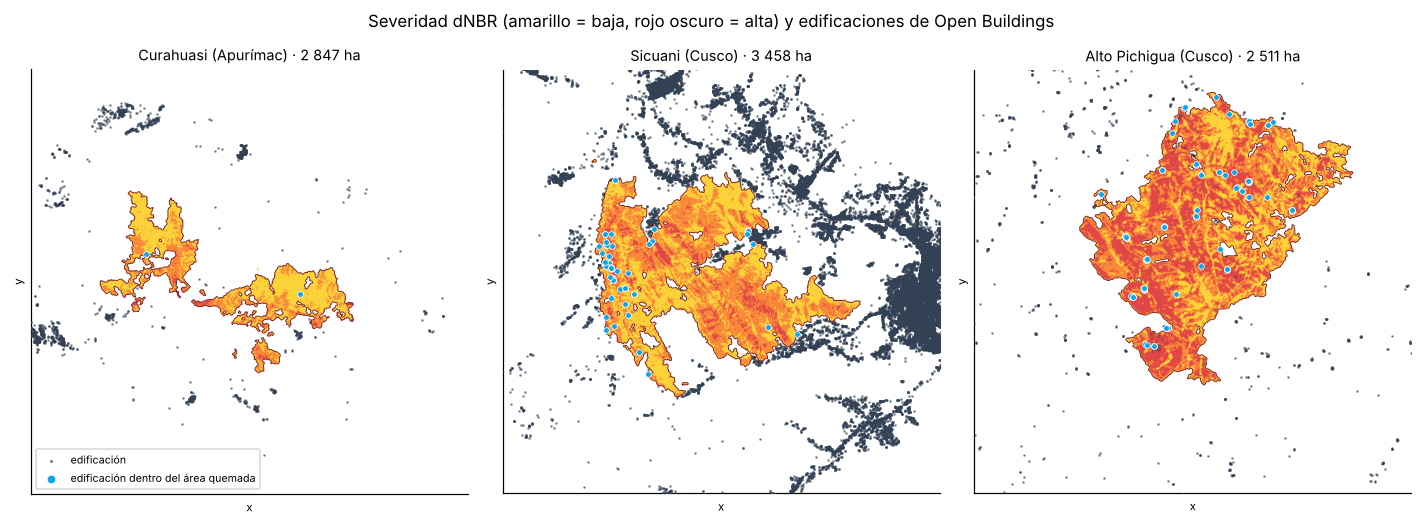

In [12]:
def mapa(ax, evento, titulo):
    p = perimetros.set_index("evento").loc[evento]
    with rasterio.open(DATOS / f"dnbr_{evento}.tif") as src:
        a = src.read(1).astype(float); b = src.bounds
    rgba = np.zeros(a.shape + (4,))
    for k, c in COLORES.items():
        rgba[a == k] = list(plt.matplotlib.colors.to_rgba(c, 0.85))
    ax.imshow(rgba, extent=[b.left, b.right, b.bottom, b.top], zorder=2)
    e = edif[edif.evento == evento]
    ax.scatter(e.longitude, e.latitude, s=0.6, c="#334155", alpha=0.5, zorder=3, label="edificación")
    ax.scatter(e[e.severidad > 0].longitude, e[e.severidad > 0].latitude, s=14, c="#0ea5e9",
               edgecolors="white", linewidths=0.5, zorder=4, label="edificación dentro del área quemada")
    gpd.GeoSeries([p.geometry]).boundary.plot(ax=ax, color="#7f1d1d", linewidth=0.6, zorder=3)
    ax.set_xlim(b.left, b.right); ax.set_ylim(b.bottom, b.top)
    ax.set_title(titulo, fontsize=9.5); ax.set_xticks([]); ax.set_yticks([])

fig, axs = plt.subplots(1, 3, figsize=(13, 4.8))
mapa(axs[0], "E41216", "Curahuasi (Apurímac) · 2 847 ha")
mapa(axs[1], "E38662", "Sicuani (Cusco) · 3 458 ha")
mapa(axs[2], "E39747", "Alto Pichigua (Cusco) · 2 511 ha")
axs[0].legend(loc="lower left", fontsize=7, frameon=True, markerscale=1.5)
fig.suptitle("Severidad dNBR (amarillo = baja, rojo oscuro = alta) y edificaciones de Open Buildings",
             fontsize=11)
plt.tight_layout()
Path("figuras").mkdir(exist_ok=True)
plt.savefig("figuras/mapa_incendios_edificaciones.png", dpi=150, bbox_inches="tight")
plt.show()

## 9 · Hallazgos con números

In [13]:
tot = exposicion.sum(numeric_only=True)
s = exposicion.set_index("distrito")
dentro_sev = quemadas.groupby("evento").size()
print(f"1. Los 7 incendios quemaron {tot.ha_quemadas:,.0f} ha. Solo {int(tot.dentro):,} edificaciones "
      f"quedaron dentro de la huella, pero {int(tot['≤1 km']):,} están a 1 km o menos y "
      f"{int(tot['≤5 km']):,} a 5 km o menos.")
print(f"2. Sicuani concentra el riesgo: {int(s.loc['Sicuani', '≤1 km']):,} edificaciones a ≤ 1 km "
      f"({s.loc['Sicuani', '≤1 km'] / tot['≤1 km']:.0%} del total de los 7 incendios); "
      f"{int(s.loc['Sicuani', '≤500 m']):,} están a ≤ 500 m del borde quemado: el fuego llegó a la periferia de la ciudad.")
print(f"3. Alto Pichigua (Espinar) es el caso opuesto: pocas edificaciones, pero "
      f"{int(s.loc['Alto Pichigua', 'dentro'])} quedaron dentro del área quemada, "
      f"{int((quemadas[quemadas.evento == 'E39747'].severidad >= 3).sum())} con severidad moderada alta o alta: "
      f"estancias altoandinas dispersas.")
print(f"4. Curahuasi, el incendio activo más grande, tocó solo {int(s.loc['Curahuasi', 'dentro'])} "
      f"edificaciones: {int(s.loc['Curahuasi', '≤1 km'])} a ≤ 1 km.")
print(f"5. Población: {exposicion.poblacion_5km.sum():,.0f} personas viven a ≤ 5 km de los focos "
      f"(WorldPop 2020); {s.loc['Sicuani', 'poblacion_5km']:,.0f} en Sicuani "
      f"({s.loc['Sicuani', 'poblacion_5km'] / exposicion.poblacion_5km.sum():.0%}).")

1. Los 7 incendios quemaron 13,297 ha. Solo 163 edificaciones quedaron dentro de la huella, pero 6,169 están a 1 km o menos y 57,277 a 5 km o menos.
2. Sicuani concentra el riesgo: 4,653 edificaciones a ≤ 1 km (75% del total de los 7 incendios); 2,700 están a ≤ 500 m del borde quemado: el fuego llegó a la periferia de la ciudad.
3. Alto Pichigua (Espinar) es el caso opuesto: pocas edificaciones, pero 82 quedaron dentro del área quemada, 8 con severidad moderada alta o alta: estancias altoandinas dispersas.
4. Curahuasi, el incendio activo más grande, tocó solo 2 edificaciones: 74 a ≤ 1 km.
5. Población: 58,282 personas viven a ≤ 5 km de los focos (WorldPop 2020); 44,869 en Sicuani (77%).


## 10 · Limitaciones

- **Un foco de calor no es un incendio, y una huella dNBR no es el área oficial.** Uso el
  dNBR del monitor del curso; no reemplaza a SERFOR, COEN ni INDECI.
- **Las nubes esconden el fuego.** Entre 0 % y 16 % de cada zona no tuvo dato limpio en
  Sentinel-2: las hectáreas son un piso.
- **Open Buildings es de 2023 o antes.** Una vivienda construida después no aparece, y una
  que el fuego destruyó sigue apareciendo. No mide daño, mide exposición.
- **Edificación ≠ vivienda ≠ familia.** Un techo puede ser corral, depósito o local comunal.
  En zonas rurales andinas el modelo también confunde techos de calamina con rocas
  (por eso filtro confianza ≥ 0,70).
- **Distancia en línea recta.** No considera quebradas, viento ni pendiente.

## 11 · Exportar para el dashboard 3D

In [14]:
salida = {"resumen": exposicion.to_dict(orient="records"),
          "zonas": zonas.to_dict(orient="records")}
Path("dashboard").mkdir(exist_ok=True)
with open("dashboard/resumen.json", "w", encoding="utf-8") as f:
    json.dump(salida, f, ensure_ascii=False, default=float)
print("listo: dashboard/resumen.json")

listo: dashboard/resumen.json
